![image.png](presentation_slide.svg)

![image.png](model-acceleration-outline.svg)

# 1.基础知识

![image.png](number-formats-svg1.svg)

## 不同数值格式的参数存储方式及范围

### 浮点格式

**1. FP32 (单精度浮点)**
- **存储结构**：32位 = 1位符号 + 8位指数 + 23位尾数
- **工作原理**：值 = (-1)^符号位 × 2^(指数-127) × (1.尾数)
- **范围**：约 ±1.18×10^-38 到 ±3.4×10^38
- **精度**：约7位十进制数字

**2. FP16 (半精度浮点)**
- **存储结构**：16位 = 1位符号 + 5位指数 + 10位尾数
- **工作原理**：值 = (-1)^符号位 × 2^(指数-15) × (1.尾数)
- **范围**：约 ±6.0×10^-8 到 ±6.5×10^4
- **精度**：约3-4位十进制数字
- **特点**：节省内存和带宽，但精度和范围大幅降低

**3. BF16 (脑浮点)**
- **存储结构**：16位 = 1位符号 + 8位指数 + 7位尾数
- **工作原理**：与FP32使用相同的指数位，但截断了尾数
- **范围**：与FP32相同，约 ±1.18×10^-38 到 ±3.4×10^38
- **精度**：约2-3位十进制数字
- **特点**：保留FP32的动态范围，牺牲部分精度，在神经网络训练中表现优异

### 整数格式

**4. INT8 (8位整数)**
- **存储结构**：8位 = 1位符号 + 7位数值（有符号）或 8位数值（无符号）
- **范围**：-128到127（有符号）或 0到255（无符号）
- **特点**：在量化深度学习模型中常用，大幅减少模型大小和计算量

**5. INT4 (4位整数)**
- **存储结构**：4位 = 1位符号 + 3位数值（有符号）或 4位数值（无符号）
- **范围**：-8到7（有符号）或 0到15（无符号）
- **特点**：极致压缩，需要特殊量化技术保持精度，主要用于推理阶段


## Llama 13B 显存占用对比

| 精度类型 | 显存占用 |
|----------|-----------|
| FP32     | 52GB      |
| FP16     | 26GB      |
| Int8     | 13GB      |
| Int4     | 6.5GB     |



# 2. 量化

## 2.1 为什么要量化

把Float类型（FP32、FP16）的模型参数和激活值，用整数（Int8、Int4）来代替，  
同时还可能减少量化后模型推理的误差。

带来的好处：

1. 减少模型的存储空间和显存的占用。  
2. 减少显存和TensorCore之间的数值传输量，从而加快模型推理时间。  
3. 量卡对整数运算速度快于浮点型数据，从而加快模型推理时间。

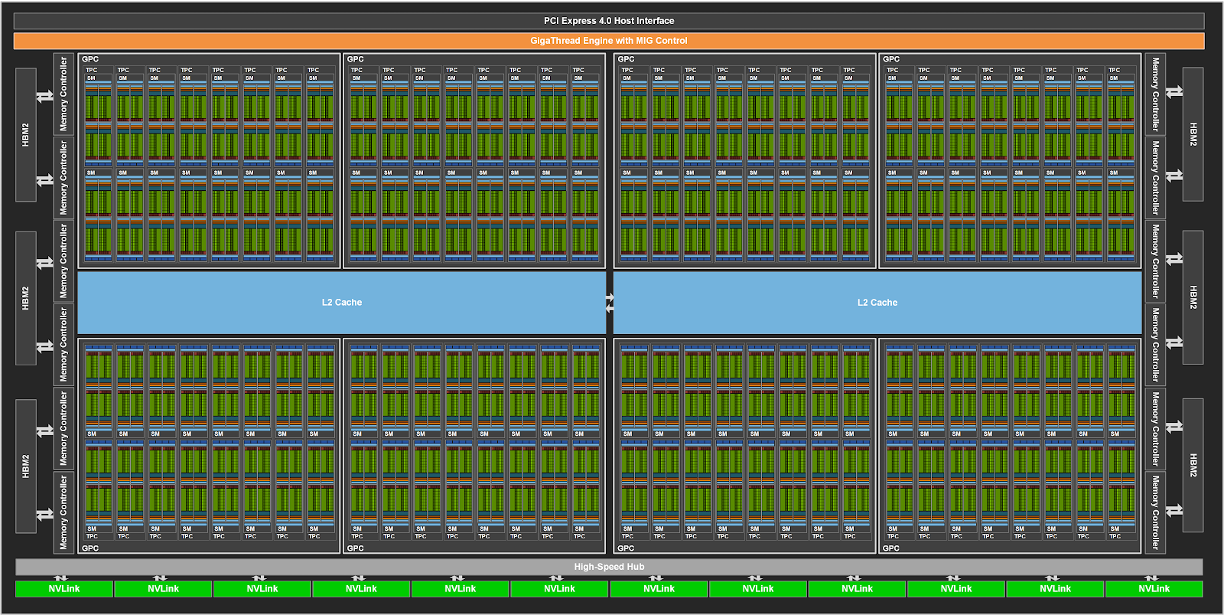

## 2.2 怎么进行量化和反量化

$x_{1f} \rightarrow \text{量化} \rightarrow x_{1q}$  
$x_{1q} \rightarrow \text{反量化} \rightarrow x_{2f}$  

让 $x_{2f}$ 尽可能接近 $x_{1f}$


![image.png](quantization-diagram.svg)

![image.png](quantization-diagram1.svg)

$$
X_f W_f = (X_q - Z_x) \cdot s_x \; @ \; (W_q - Z_w) \cdot s_w \\
= s_x \cdot s_w \left( X_q W_q - X_q Z_w - W_q Z_x + Z_x Z_w \right)
$$


说明：
- `@` 表示矩阵乘法（可换成 `\cdot` 或 `\times` 根据语境）；
- `s_x`、`s_w` 是量化尺度；
- `Z_x`、`Z_w` 是零点（zero point）；
- `X_q`、`W_q` 是量化后的输入和权重；
- `X_f`、`W_f` 是反量化后的结果或浮点表示。

## 2.3 大模型神经网络中的量化

![image.png](attention-blocks-svg-chinese.svg)

- **训练后动态量化（Post Dynamic Quantization）**  
  不使用校准数据集，直接对每一层 layer 通过量化公式进行转换。  
  👉 代表方法：`LLM.int8()` 和 `QLoRA`

- **训练后校正量化（Post Calibration Quantization）**  
  需要输入有代表性的校准数据集，根据模型每一层 layer 的输入输出调整量化权重。  
  👉 代表方法：`GPTQ`、`AWQ`

### 训练后动态量化

1. 将训练好的模型权重量化为int8，并保存量化参数。  
2. 在推理推理时，对每一层输入先fp32转换成int8，然后进行int8运算后再转化为int8。  
3. 在每一层前插入fp32转换成int8的逻辑或在后面进行反量化计算。  
4. 在每一层输出前将int8结果量化为fp32。  
5. 将该运算结果传入到下一层。

![image.png](flowchart.svg)

#### 训练后动态量化的问题：

1. 每一次推理每一层都要对输入统计量化参数，耗时。  
   > 用有代表性的数据跑一遍整个网络，通过统计得到每层大概的量化参数。

2. 每一层计算完成都转化为 fp32，有点显存，占用显存带宽。  
   > 这一层的输出是下一层的输入，下一层还是要量化，不如在这一层直接量化好再传给下一层。


### 训练后校正量化

1. 将训练好的模型权重量化为int8，并保存量化参数。  
2. **校准（calibration）**：利用一组有代表性的校准数据进行处理，用这些数据在神经网络每一层产生的激活值均值或高值估算量化参数。这样就不再推理时每次依赖模型实际激活值估算量化参数。  
3. 在每一层对上层的int8权重和int8激活值进行计算。  
4. 在每一层输出时将结果反量化为fp32，同时根据校准产生的激活值量化参数，把激活值量化为int8，把量化参数嵌入反量化函数逻辑中。  
5. 将int8的激活值和它的量化参数传入到下一层。

![image.png](flowchart-white-bg.svg)

## 2.4 Bnb 8bit量化

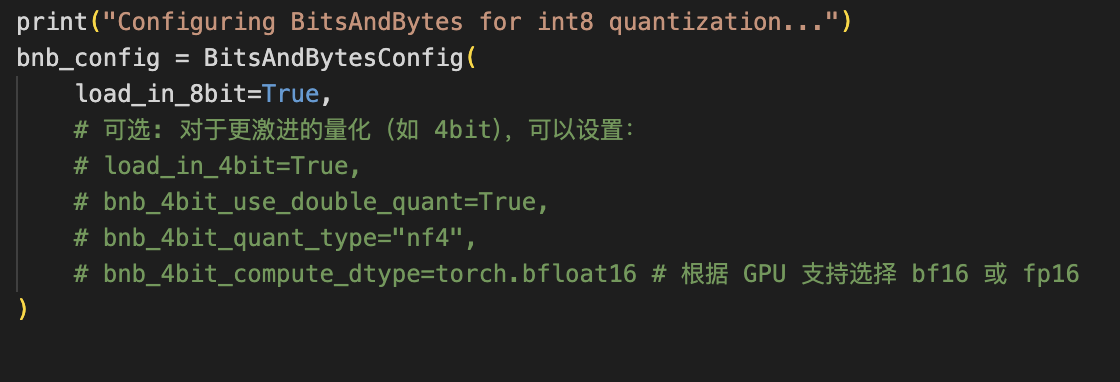

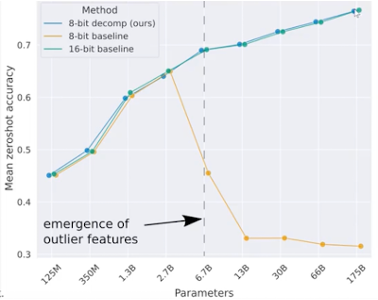

#### 为什么传统的量化方式随着模型参数的上升性能会断崖式下降呢？

![image.png](quantization-mapping.svg)

**原始特征：**  
[-0.10, -0.23, **57.0**, 0.08, -0.38, -0.28, **-45**, -0.29, -2.11, 0.34, -0.53, **-67.0**]

**量化+反量化：**  
[-0.00, -0.00, **57.0**, 0.00, -0.53, -0.53, **-45**, -0.53, -2.11, 0.35, -0.53, **-67.0**]

**去除异常值后量化&反量化：**  
[-0.10, -0.23, **0.33**, 0.08, -0.38, -0.28, **-2.11**, -0.28, -2.11, 0.33, -0.53, **-2.11**]


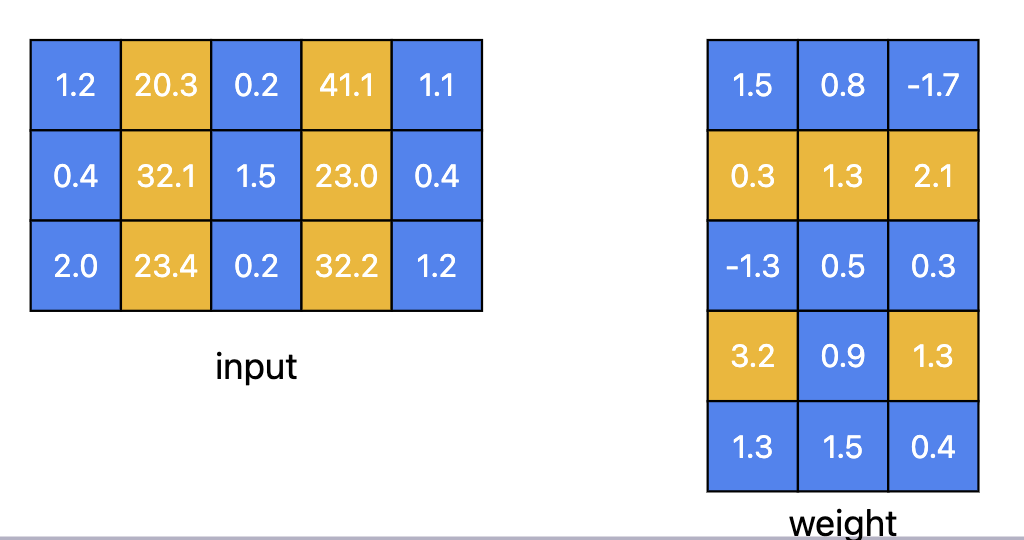

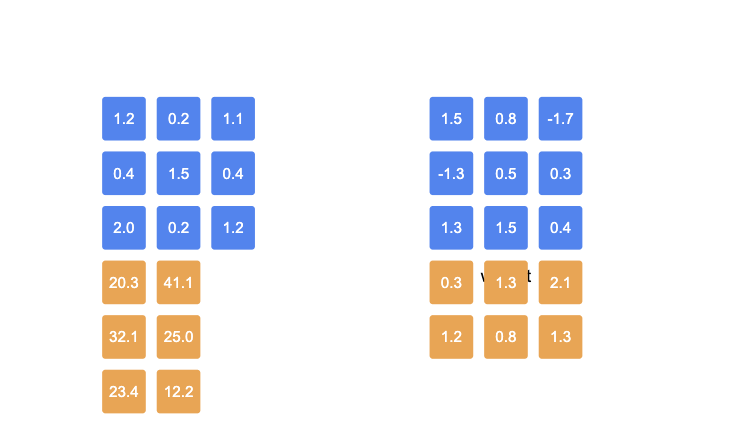

![image.png](llm-int8-diagram1.svg)

- Emergent Feature 仅占所有特征的 0.1%  
- Weight 在加载模型时量化，显存占用比 float16 减半  
- 使用 LLM.int8() 对精度几乎没有影响  
- 模型推理速度会变慢 20% 左右

## 2.5 qlora int4量化

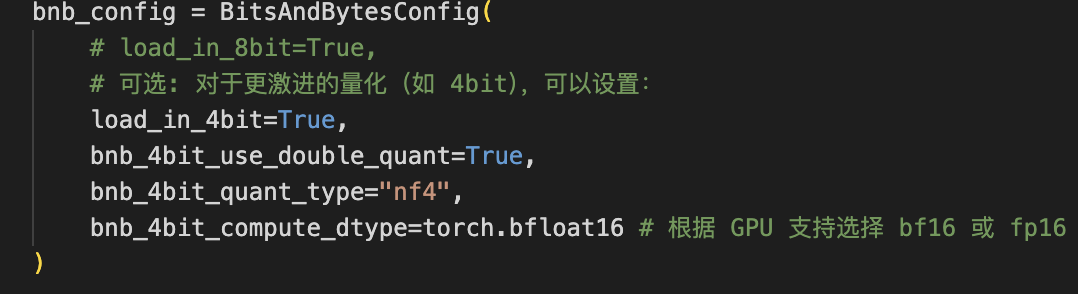

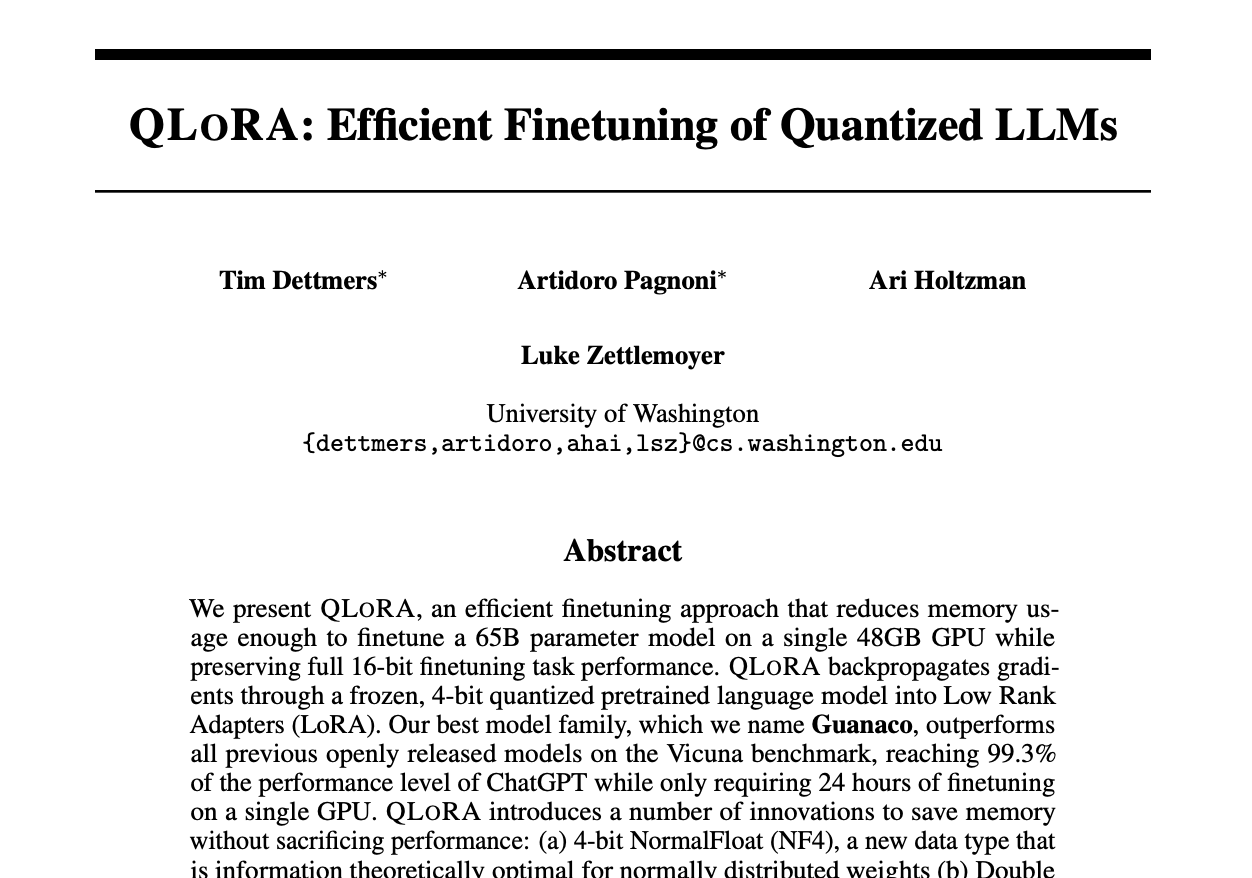

### 这篇论文的核心就是int4 量化，现在已经集成到各类训练框架中

#### 提出问题

在 NLP 领域，对于下游任务进行大规模训练语言模型的微调已经成为一种重要的做法。一般而言，我们会采用对原有的预训练模型进行全量微调的方法来适配下游任务。然而，对于大规模的模型，微调过程可能会消耗大量的内存和计算资源，使得对于模型的微调产生了一定的门槛。

---

#### 核心要点

1. **QLoRA**：通过 4-bit 量化的 BaseModel 在保持特性性能的同时减少内存使用，使模型微调的门槛大大降低。
   - 核心方法是提出了 NormalFloat 数据类型进行量化。
   - 核心思想是通过量化降低基座模型显存占用，使得 65B 规模在单 GPU 上可以完成训练。

2. **Guanaco**：新发布了一个基于 LLaMa 的微调数据集，在 Vicuna 基准测试中的表现优于所有以前公开发布的模型。
   - 微调的数据是 9 条，4bit 的 9338 数据用于使用 4bit 的 l13B 模型微调。

3. **Misc**：指出在下游任务中存在在一定问题：针对特定下游任务训练的模型具有的优势。
   - 使用 GPT4 进行自动评价时存在先入为主的情况，无法准确评估多种主观人的角度。

4. 针对特定任务，训练数据的适用性（Suitability）和质量（Quality）相比其它因素更加重要。

5. **Outlier Matters**：大量训练数据中可能出现噪声数据。
   a. 对于愚本的表述，前缀对于模型性能的差异影响较大，模型对 outlier 的敏感更强  
   b. 稀有值很偏，集中于顶部的几列，并且在模型输出的 prefix，可能存储了一些上下文关联的重点


![image.png](histogram-visualization.svg)

### 分位量量化 Quantile Quantization

量化是将连续变量的数值变换到预定离散上的某一个值。以 4-bit 为例，映射后的参数取值只能从 {0~15} 中选一个。通常的量化方法是量化后直接连接最近的浮点值（有偏向的量化），这种量化方法需要明确参数的范围，量化后参数整体的分布与原始的分布差别很大。例如出现一个极大或极小值，可能让区间分布变得很稀疏，这种效果显著干扰模型。

为了避免这种情况，引入了分位量化（Quantile Quantization）。那么什么是分位量化呢？还是以量化到 4-bit 为例，共有 16 个数值可以选择，量化可以把每个参数数值从小到大进行排序并等分为 16 份，每一份映射一个值。这样的量化方法量化后的参数数值更均匀分布在原始分布的整体形态下。

---

### NormFloat量化

上述的量化会影响引入明显的计算开销，因为每次有参数输入进来都需要实时进行排序并转换。由于预测值的参数基本上都服从均值为 0 的高斯分布，可以找到概率密度为 1、1 的范围时，同时可以把该区域定义为 {0,1,0} 这样一个倍数，将极值设置为 1、1 的范围中。选择保留这个范围内的数据做动态的分段，不再均匀划分分布，但还是保证整体分布形态一致。

但是这种量化在每一个 batch、每一层的权重不是完全的重上了一致，就会丧失全局的精度语义。为此打一个配比，即将均值和方差都独立编码分别为 32 位，参数还是定义在 0 和 1 的范围上。

将所有x除以最大绝对值，归一化到[-1,1]之间。

| 归一化值 (Normalized Value) | 索引 (Index) |
|-----------------------------|--------------|
| -1.0                        | 0            |
| -0.6962928339986877         | 1            |
| -0.5250730514526367         | 2            |
| -0.39491748809814453        | 3            |
| -0.28444138368288635        | 4            |
| 0.18477243022823334         | 5            |
| -0.09105003625254495        | 6            |
| 0.0                         | 7            |
| 0.07958029955625534         | 8            |
| 0.16098020141124725         | 9            |
| 0.24611200194568634         | 10           |
| 0.33791524171829224         | 11           |
| 0.44070982933044434         | 12           |
| 0.5626170039176941          | 13           |
| 0.7229568362256025          | 14           |
| 1.0                         | 15           |


## 量化过程

原始值：  
\[ 1.532, -0.823, 0.412, 0.232 \]

🔵 **通过 scale 归一化**（scale = 1.532）：  
\[ 1.0, -0.537, 0.269, 0.151 \]

🔵 **查表，量化**：  
\[ 15, 2, 10, 9 \] （scale = 1.532）

---

## 反量化过程

输入量化值：  
\[ 15, 2, 10, 9 \]（scale = 1.532）

🟡 **查表，反量化**：  
\[ 1.0, -0.5250, 0.2461, 0.16093 \]

🟡 **乘以 scale**：  
\[ 1.532, -0.804, 0.377, 0.247 \]



#### 分块量化带来的问题

64个 4bit = 256 bit  
1个 32位的 scale  
额外占用：32 / 256 = 12.5%

---

#### 解决方法：双重量化

每 256 个分块的 scale 值进行一次 8bit 量化。  
额外占用从 12.5% 降低到 3.174%

---

双重量化减少了显存占用，但是反量化时要进行两次反量化，  
先对 scale 值进行反量化，然后对 tensor 值进行反量化。

#### 我们再回头看看训练的参数分别是什么含义？

## 2.6 GPTQ/AWQ/GGUF

###  GPTQ

**技术原理与特点：**
- GPTQ（Quantize-aware training 或者更常见的是离线量化策略）通常采用块状或分组权重量化（blockwise/groupwise），在保证模型精度的同时显著压缩模型体积、减小显存开销。
- 通过在离线阶段对每一层/块的权重逐步调整（逐层或逐块的最优量化方案），可以最大化保留模型精度。
- GPTQ 的常用量化范围是2～8bit，且在 4 bit 或 8 bit 量化时一般损失较小。
- 如果使用 Auto-GPTQ 版本 >= 0.4.2，可以在 CPU 上进行量化推理（推理速度有限制），同时也支持 LoRA 等微调方法对量化模型进行再训练（PEFT/LoRA）。

**优势：**
1. **性能较好**：在 4bit 或 8bit 量化下，推理速度与精度的平衡性好。
2. **灵活性**：GPTQ 在不同硬件环境上都能工作；Auto-GPTQ>=0.4.2 也可支持 CPU 场景（虽然速度会较低）。
3. **微调支持**：可结合 PEFT（LoRA 方式）对量化后的模型进行二次微调，减少硬件资源需求。

**使用场景：**
- **多 GPU 服务器**：在有限显存、需兼顾推理速度和结果准确度的场景下进行推理或小规模二次训练。
- **较大规模模型**：比如 13B、30B 级别模型，用 GPTQ 量化后节省显存，避免动辄需要高端大显存 GPU。
- **高精度需求**：希望在量化后依然保持较好效果，GPTQ 的块状量化策略有助于维持模型精度。

---

###  AWQ

**技术原理与特点：**
- AWQ（Activation-aware Weight Quantization）强调了量化时对激活分布的分析，力求在不改动模型结构、不进行大量微调的情况下，找到对每一层最优的量化比例。
- 以**后训练量化（Post-training Quantization）**为主，不需要在大规模数据集上进行完整地再训练，只需对模型的激活分布进行统计与修正。
- 量化范围亦可在 2～8bit，但目前大多数场景下主要使用 4 bit 或 8 bit。

**优势：**
1. **无需大规模训练**：通过分析并纠正模型激活分布，减少了微调资源需求和时间开销。
2. **极端低比特量化**：可将模型压缩到 2 bit～8 bit，尤其在 4 bit 或更低比特情况下仍力求维持相对合理的精度。
3. **推理速度快**：对 GPU 推理较为友好，小体积、高速访问。

**使用场景：**
- **极致压缩需求**：对推理速度、模型大小有极高要求，愿意在极端低比特（如 2 bit～4 bit）上进行探索的研究或应用。
- **环境受限**：在显存或 GPU 资源极度不足，但又希望尽可能保留模型可用性的项目。
- **仅 GPU 推理**：当前 AWQ 暂不支持在 CPU 上做推理，**也暂不支持进行微调**。

---

### llama.cpp（gguf 格式）

**技术原理与特点：**
- llama.cpp 是以 C++ 实现对 LLaMA 等衍生模型进行高效推理的项目，可在 CPU、GPU、移动端等多种设备上部署。
- **gguf 格式**是新一代的模型文件格式，用来替代之前的 ggml/ggjt 等，支持更多量化方案和新特性，使模型部署更便捷。
- 量化等级非常细化：从 2 bit 到 8 bit，每个等级还细分了多种方法（例如 q4_0、q4_K、q5_K 等），开发者/用户可根据硬件性能和精度需求自行选择。
- llama.cpp 支持 LoRA 方式对量化后的模型进行微调，保留在 CPU/GPU 上进行增量训练或推理的能力。

**优势：**
1. **跨平台支持**：可在手机、树莓派、单卡小显存等多环境下运行，尤其在 CPU 场景下表现突出。
2. **量化选择灵活**：提供了丰富的量化方式，可在速度、精度、模型大小之间进行取舍。
3. **生态活跃**：llama.cpp 社区活跃且更新快，经常针对新模型或新量化策略做支持。
4. **微调支持**：已经支持对量化模型进行 LoRA 微调（例如 QLoRA、PEFT+LoRA）。

**使用场景：**
- **多环境部署**：手机端、PC 端、内存受限环境等，对易用性和通用性有较高要求。
- **离线场景**：不能依赖云服务器，需要本地 CPU 推理，保证数据隐私或提升可控性。
- **中小型项目研究**：对模型深度定制或二次微调（LoRA）进行实验，llama.cpp 提供了灵活的开发体验。


### 速率测试

| 量化方式 | 运行设备     | 级别  | 初始显存占用 | 推理速度 (限制512, token/s) | 推理速度 (限制1024, token/s) | 推理速度 (限制2048, token/s) |
|----------|--------------|-------|--------------|-----------------------------|------------------------------|------------------------------|
| BnB      | RTX4090 * 1  | 4bit  | 21600MiB     | 11.5                        | 9.1                          | 9.8                          |
| GPTQ     | RTX4090 * 1  | 4bit  | 21810MiB     | 16.8                        | 15.4                         | 13.0                         |
| AWQ      | RTX4090 * 1  | 4bit  | 22202MiB     | 26.1                        | 21.3                         | 15.8                         |
| 无量化   | A800 * 1     | 16bit | 67000MiB     | 13.7                        | 11.5                         | 11.1                         |

# 3. 蒸馏/剪枝

### 3.1 蒸馏

#### 原理
将待压缩的模型作为教师模型，将体积更小的模型作为学生模型，让学生模型在教师模型的监督下进行优化，将学生模型学习到教师模型的概率分布，通过kl散度进行控制。
#### 方法
对于大模型的知识蒸馏，主要分为两种：
##### 其一、黑盒知识蒸馏。
使用大模型生成数据，通过这些数据去微调更小的模型，来达到蒸馏的目的。缺点是蒸馏效率低，优点是实现简单。
![image.png](distillation-diagram.svg)
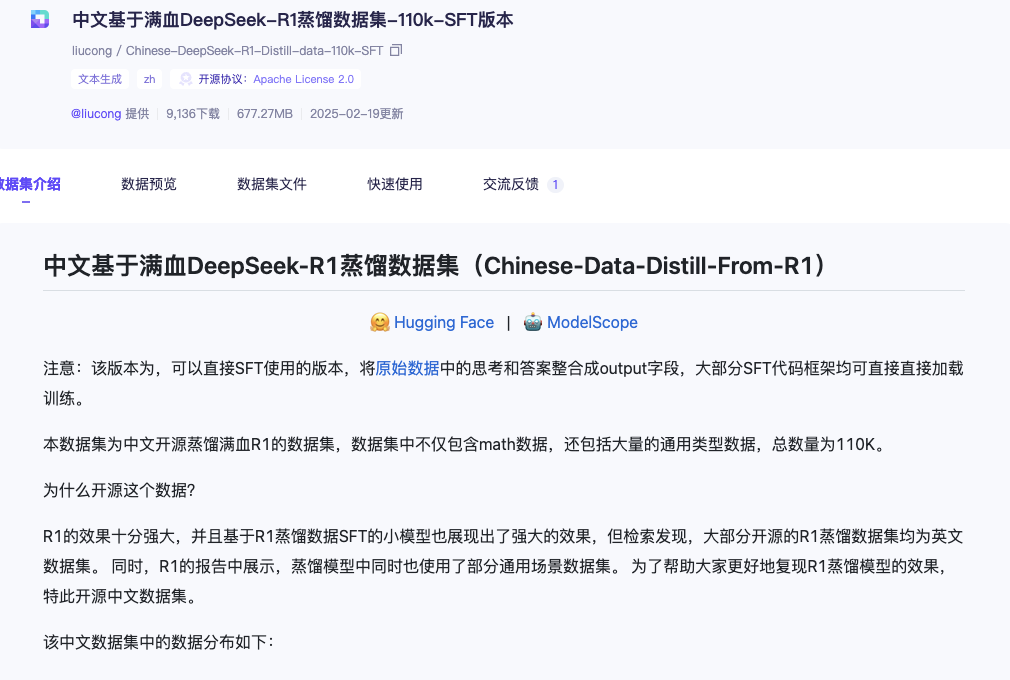


##### 其二、白盒知识蒸馏。
获取学生模型和教师模型的输出概率分布（或者中间隐藏层的概率分布），通过kl散度将学生模型的概率分布向教师模型对齐。
下面主要介绍和测试白盒知识蒸馏：
白盒知识蒸馏主要在于模型分布的对齐，模型分布对齐主要依赖kl散度：

![image.png](whitebox-distillation-diagram.svg)

![image.png](分布.png)

![image.png](分布2.png)

1. **流程概述**：
   - 相同的输入数据同时传入教师模型（预训练大模型）和学生模型（待训练小模型）
   - 分别获取两个模型的输出概率分布（软标签）
   - 使用KL散度计算两个分布之间的差异
   - 通过反向传播仅更新学生模型的参数，使其输出分布逐渐接近教师模型

2. **关键机制**：
   - **KL散度对齐**：KL散度（Kullback-Leibler散度）用于衡量两个概率分布之间的差异，公式为D_KL(P||Q) = ∑ P(x) log(P(x)/Q(x))
   - **软标签传递**：教师模型的输出不仅包含最可能的类别，还包含各个类别的概率分布，这些"软标签"比硬标签包含更丰富的信息
   - **混合损失函数**：通常结合交叉熵损失（针对真实标签）和KL散度损失（针对教师分布）

3. **可选的中间层对齐**：
   - 除了最终输出层，还可以对齐模型的中间隐藏层表示
   - 这可以帮助学生模型更好地学习教师模型的内部特征表示

黑盒蒸馏有几个显著的优势，主要体现在其灵活性和实用性方面：

1. **实现简单**：黑盒蒸馏不需要访问教师模型的内部结构、参数或中间层输出，只需要能够获取教师模型对输入的响应（输出）即可。这大大降低了实施难度。

2. **适用范围广**：可以应用于任何能提供输出的模型，甚至可以用于API形式提供的模型（如OpenAI的GPT系列或Claude等商业模型），无需获取模型权重。

3. **模型异构性支持**：教师模型和学生模型可以有完全不同的架构、大小和设计，因为只关注输入-输出对应关系，不需要层级匹配。

4. **数据扩充能力**：可以使用教师模型生成大量无标签数据的标注，创建专门针对特定领域或任务的合成数据集。

5. **隐私保护**：当教师模型包含敏感数据或专有技术时，黑盒蒸馏允许知识转移而不泄露模型内部结构。

6. **部署灵活性**：可以选择性地只蒸馏模型在特定领域的能力，而不是完整复制所有功能。

7. **无需模型权重访问权限**：对于商业模型，往往无法获取完整的模型权重，黑盒蒸馏是唯一可行的知识迁移方案。

黑盒蒸馏虽然在效率上可能不如白盒蒸馏，但其实用性和适应性使其在许多实际应用场景中成为首选方法，特别是在处理专有模型或跨架构知识转移时。

# 在实战中，我们也将实现qwen2.5的黑盒蒸馏

### 3.2 剪枝（现在用的很少）

![image.png](pruning-neural-network.svg)

![image.png](pruning-diagram.svg)

1. 原始大模型
首先我们有一个完整训练好的大模型（如GPT、LLaMA等），通常包含数十亿甚至数千亿参数。
2. 参数重要性评估
剪枝的核心是确定哪些参数可以移除：

基于幅值的评估：删除绝对值小的权重，因为它们对输出的贡献较小
基于梯度的评估：计算参数对损失函数的影响程度
基于激活的评估：评估神经元的激活情况，移除"死"神经元
基于注意力头的评估：评估Transformer模型中各注意力头的重要性

3. 执行剪枝
根据重要性评估结果，有两种主要剪枝方式：

非结构化剪枝：移除单个权重参数，产生稀疏矩阵
结构化剪枝：移除整个神经元、注意力头或层，保持矩阵结构规整，更便于硬件加速

4. 微调训练
剪枝后，模型性能通常会下降，需要进行微调：

使用原始训练数据或高质量数据子集
较低学习率，防止过拟合
适应新的稀疏结构

5. 性能评估
评估剪枝后模型的：

准确率/任务表现
推理速度提升
内存占用减少
在各种任务上的泛化能力

对于不同大小和类型的模型，剪枝策略需要具体调整，这是一个反复迭代的过程，直到达到理想的模型大小与性能平衡点。

**但是这个过程极其复杂，且不稳定，现在已经很少使用**

# 4 Flash Attention

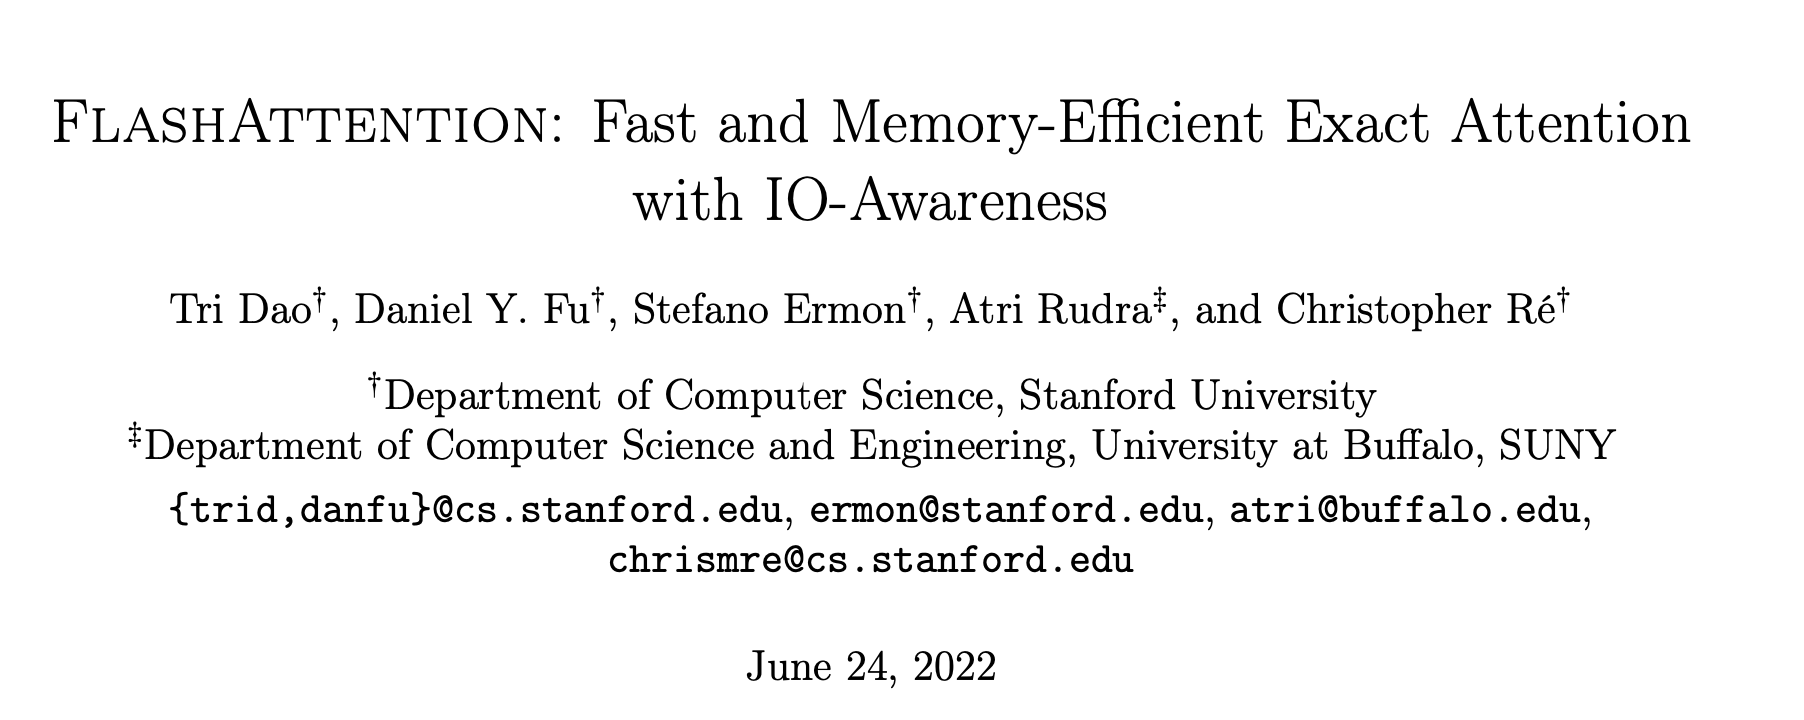

### Flash Attention并没有从transformer的矩阵计算层面去进行加速，而是在io层面进行加速，所有没有任何精度损失

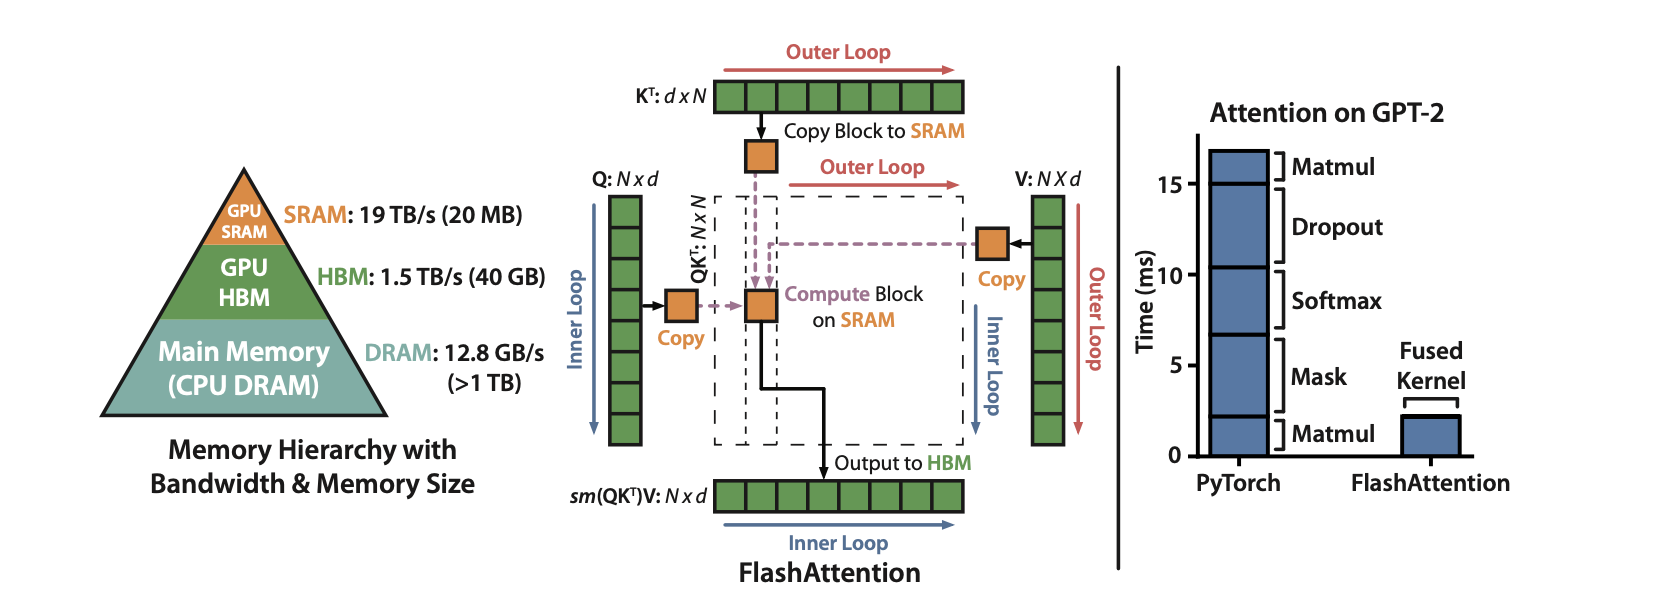

### 我们来回忆一下Transformer的计算过程

![image.png](simplified-hardware-flow.svg)

矩阵 Q, K, V ∈ ℝ^(N×d) 存储在HBM。
1. 从HBM加载Q,K到SRAM
2. 计算出S = QKᵀ
3. 将S写回到HBM
4. 将S加载到SRAM
5. 计算P = softmax(S)
6. 将P写出到HBM
7. 从HBM加载P和V到SRAM
8. 计算O = PV
9. 把O写出到HBM
10. 返回O

#### Compute-Bound:
大的矩阵乘法，多channel的卷积

#### Memory-Bound:
按位操作，Relu，Dropout
规约操作，sum，softmax

对于Memory-Bound的优化一般是进行fusion融合操作。不对中间结果缓存，减少HBM的访问。
fusion可以提升效率，但是模型训练时需要保留中间结果，反向传播时使用。

![image.png](attention-mechanism-diagram.svg)

![image.png](direct-data-flow.svg)

### 但是这里面有一个问题，softmax怎么办

#### 计算softmax需要一整行的数据！！！

#### 首先了解一下safe softmax

$$
\text{safe softmax}(x_i) = \frac{e^{x_i - \max(x)}}{\sum_{j=1}^{N} e^{x_j - \max(x)}}
$$

在 Softmax 公式中，从每个输入元素 x_i（以及分母中的 x_j）中减去 max(x)（即输入向量 x 中的最大值）是为了 提高数值稳定性 (Numerical Stability)，防止计算过程中出现上溢 (Overflow) 或下溢 (Underflow) 的问题。

具体原因如下：

**防止上溢 (Overflow):**

Softmax 函数涉及指数运算 e^x。如果输入向量 x 中包含很大的正数，那么 e^x 的结果可能会变得非常巨大，超出计算机浮点数能够表示的最大范围，导致上溢（结果变成 Infinity 或 Inf）。

如果分子或分母中的任何一项变成 Inf，计算结果就可能变成 NaN (Not a Number) 或者不准确的 0 或 1。

通过减去 max(x)，我们确保了指数函数的输入 x_i - max(x) 不会大于 0。最大的输入值变成了 0，其指数结果 e^0 = 1。其他所有输入都将是负数，其指数结果将在 (0, 1) 区间内。

这样，指数运算的结果就不会变得无限大，从而避免了上溢问题。

**缓解下溢 (Underflow) 影响:**

如果输入向量 x 中包含绝对值很大的负数（例如 -1000），那么 e^x 的结果会非常接近于 0。如果向量中所有的值都导致 e^x 小于计算机浮点数能表示的最小正数，就可能发生下溢（结果变成 0）。

如果在计算分母的求和时，所有项都因下溢变成 0，那么分母就会是 0，导致除以零错误（结果为 Inf 或 NaN）。

通过减去 max(x)，至少有一个元素（即原先最大的元素）的指数输入变成了 0，其结果为 e^0 = 1。这就保证了分母的求和中至少有一个值为 1 的项，使得分母不会因为所有项都下溢而变成 0。虽然其他项可能仍然非常小甚至下溢为 0，但这通常不会影响最终结果的准确性，因为它们对总和的贡献本来就微乎其微。

关键点：

数学等价性： 从 Softmax 的定义可以看出，给所有输入 x_i 加上或减去一个常数 C 并不会改变最终的输出结果：
softmax(x_i) = e^(x_i) / sum(e^(x_j)) = (e^(x_i) * e^(-C)) / (sum(e^(x_j) * e^(-C))) = e^(x_i - C) / sum(e^(x_j - C))
我们选择 C = max(x) 正是为了利用这个性质来获得数值稳定性。

实践标准： 在实际编程实现 Softmax 时，减去最大值是一种标准的做法，几乎所有的深度学习框架（如 TensorFlow, PyTorch）内部都是这样实现的，以确保计算的鲁棒性。

#### Softmax计算过程

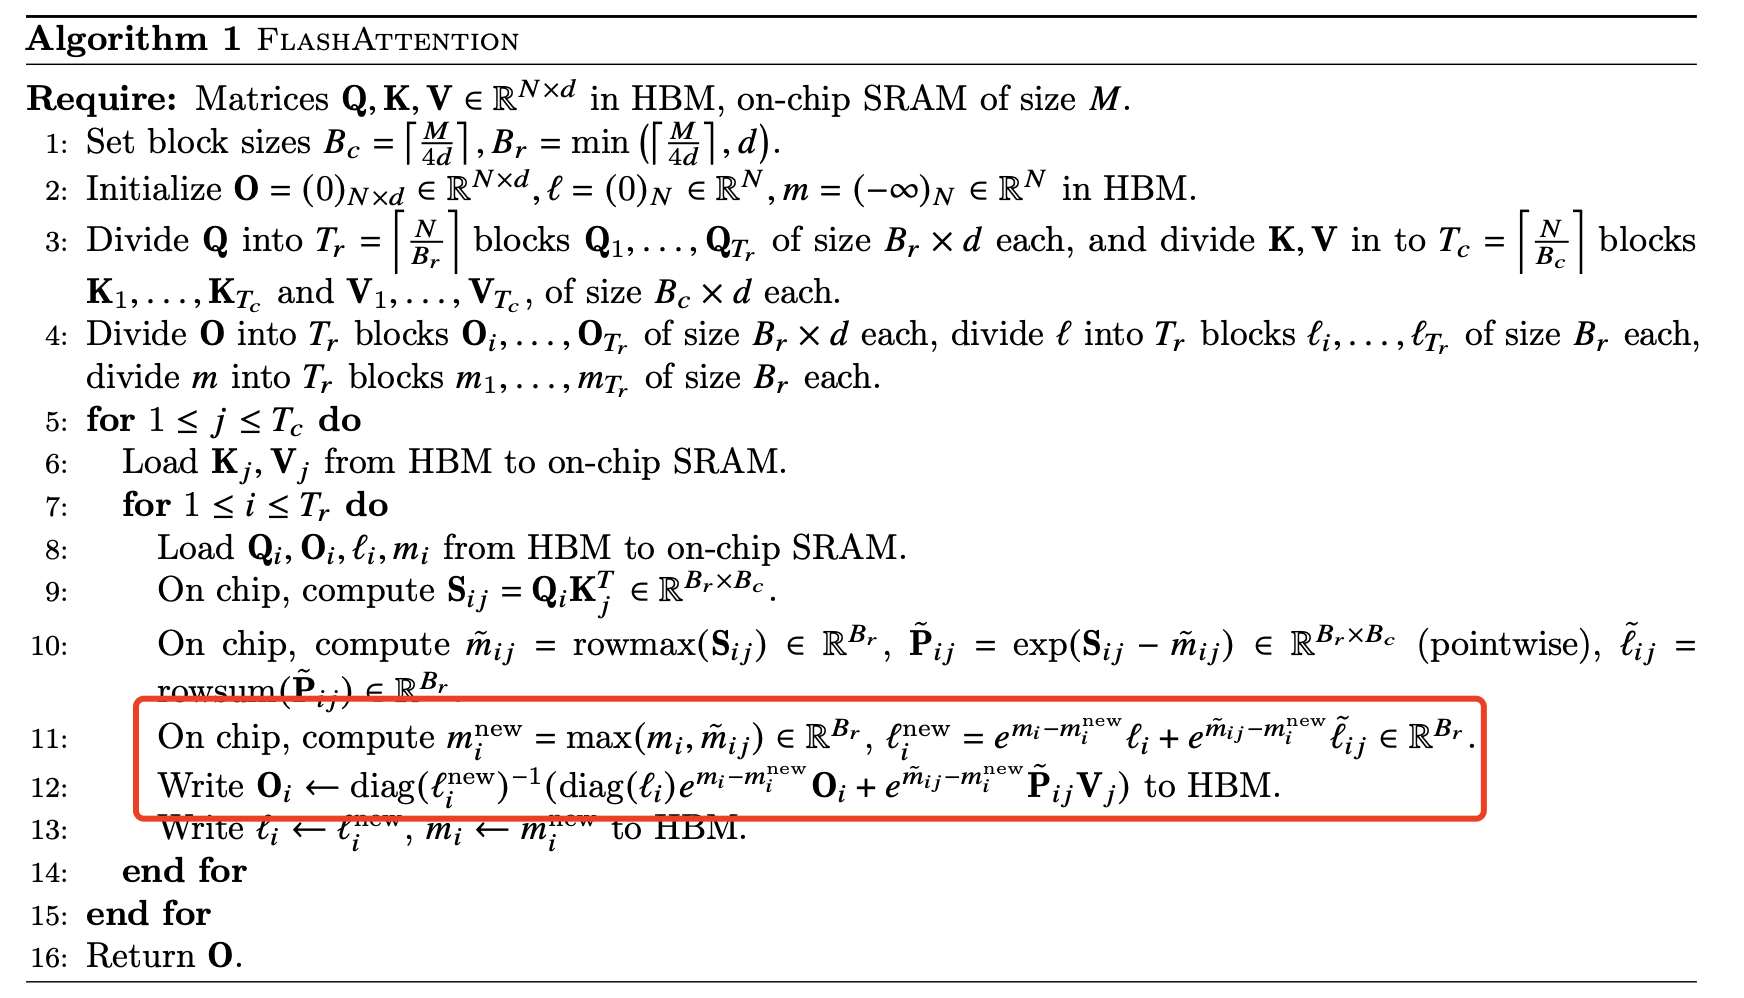

### 核心思想是：在处理每个数据块时，迭代地更新 Softmax 的统计量（最大值和归一化分母）以及最终的加权输出值。


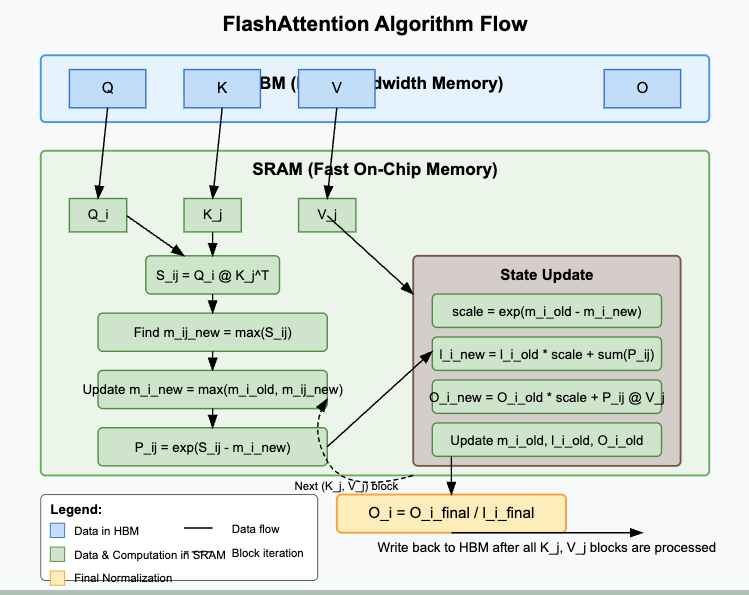

1. **内存层次结构**：
   - 顶部浅蓝色区域是 HBM（高带宽内存），存储完整的 Q、K、V 和最终输出 O 矩阵
   - 中间浅绿色区域是 SRAM（片上快速内存），用于块计算和状态更新

2. **数据流程**：
   - 从 HBM 加载 Q_i、K_j 和 V_j 块到 SRAM
   - 在 SRAM 中计算 S_ij = Q_i @ K_j^T
   - 找到当前块的最大值 m_ij_new
   - 更新全局最大值 m_i_new = max(m_i_old, m_ij_new)
   - 计算 P_ij = exp(S_ij - m_i_new)

3. **状态更新（右侧棕色框）**：
   - 计算缩放因子 scale = exp(m_i_old - m_i_new)
   - 更新累积分母 l_i_new = l_i_old * scale + sum(P_ij)
   - 更新累积输出 O_i_new = O_i_old * scale + P_ij @ V_j
   - 更新状态变量为下一次迭代做准备

4. **最终归一化**：
   - 所有 K_j、V_j 块处理完成后，计算 O_i = O_i_final / l_i_final
   - 将结果写回 HBM

5. **迭代过程**：
   - 虚线表示迭代到下一个 (K_j, V_j) 块，重复这个过程直到处理完所有的块

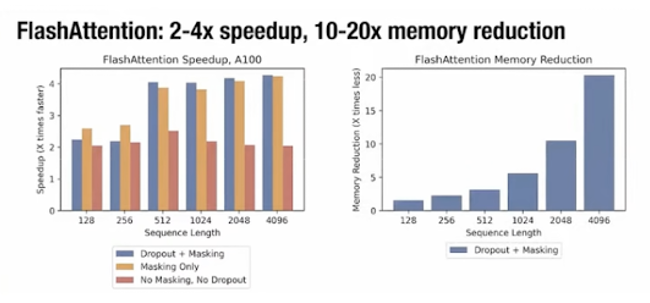

# 5. KV Cache

- KV Cache应用于推理阶段（也就是K、V的值是不变的）
- KV Cahce只存在于Decoder解码器中
- 它的目的是为了加速Q@K@V的两次矩阵相乘时的速度
- KV Cache会加大内存占用

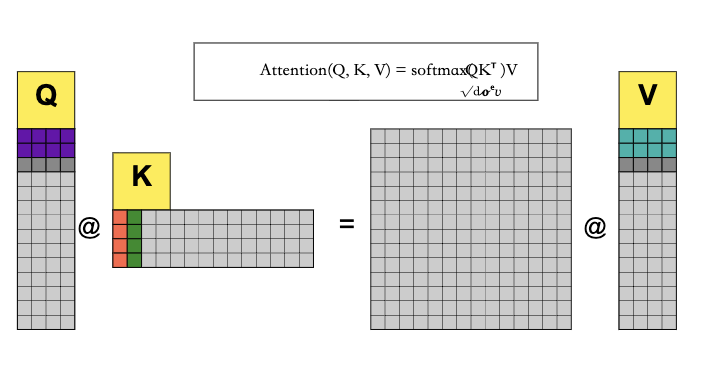

### 不用KV cache

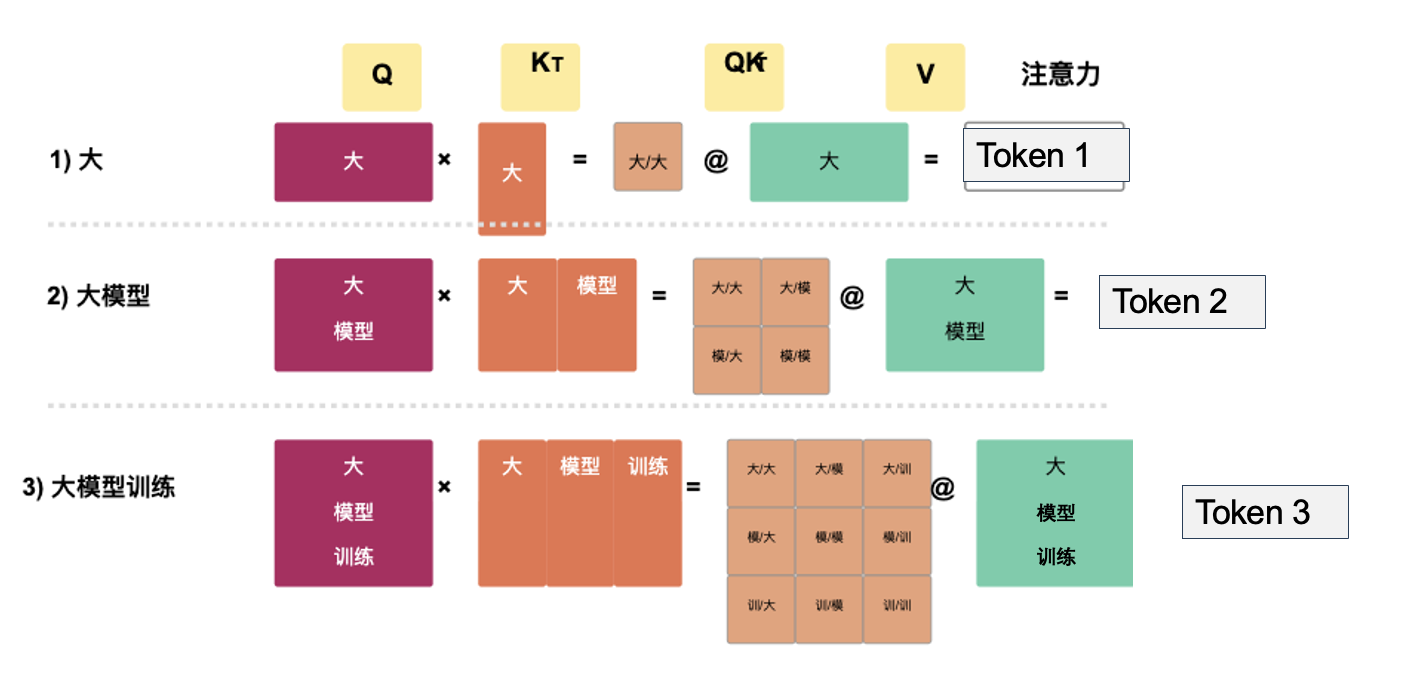

### 用KV Cache

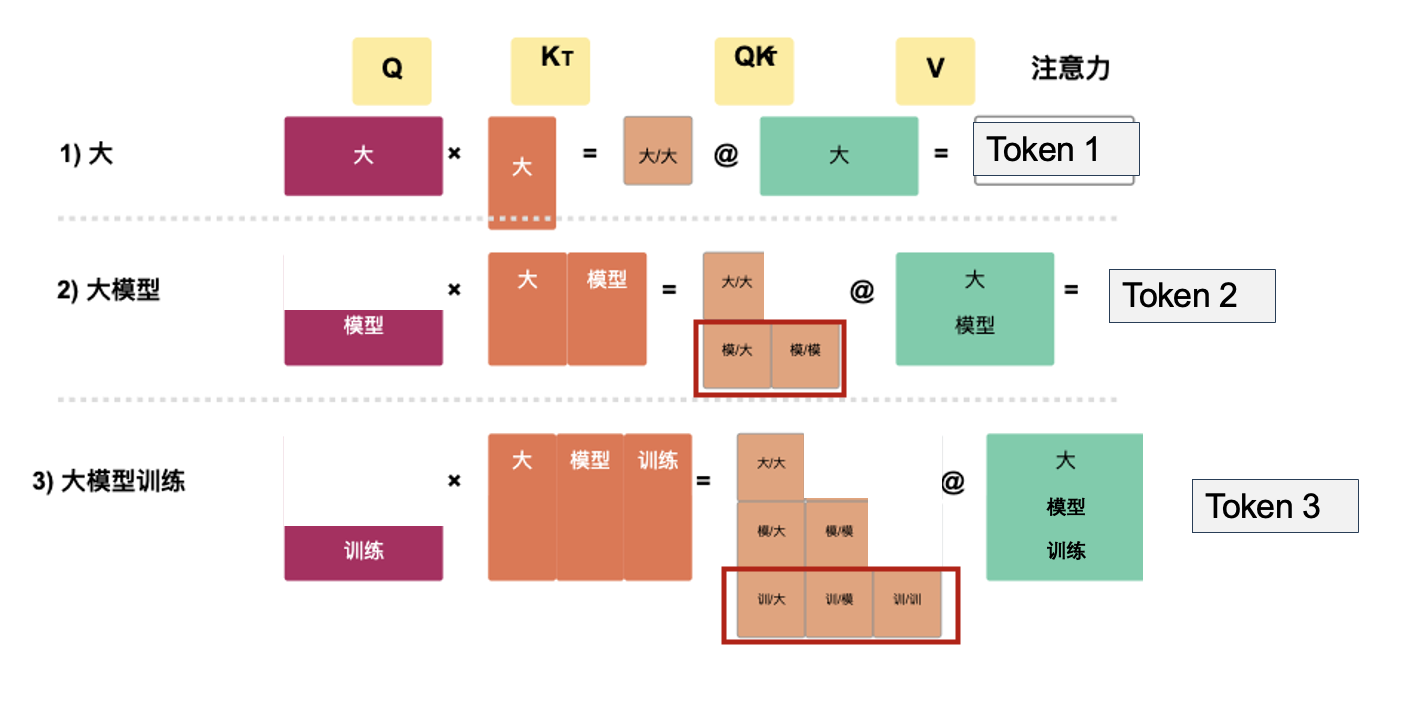

如果kv向量计算完成之后储存下来，新的token过来之后，q只需要依次和前面的kv相乘，那么相当于一个【1，dim】的Q去和一个【N，dim】的K相乘，只需要进行N次运算
所以时间复杂度从**O（N^2）降低到了O（N）**

### KV cache的显存占用

**`显存占用 = 2 * 精度 * 层数 * embed维度 * 最大序列长度 * 批次大小`**

让我们逐步拆解这个公式的每一项：

1.  **`2`**: 这个数字代表了需要缓存的两种不同的向量：**K (Key) Cache** 和 **V (Value) Cache**。在 Transformer 的自注意力机制（Self-Attention）中，每个 token 会生成 Query (Q), Key (K), 和 Value (V) 三种向量。在生成式任务（如文本生成）中，为了避免重复计算前面所有 token 的 K 和 V 向量，模型会将它们缓存起来。因此，对于每个 token，在每个注意力层，都需要存储一个 K 向量和一个 V 向量，所以是两份数据。

2.  **`精度` (Precision)**: 指的是存储 K 和 V 向量中每个数值所用的数据类型占用的字节数。
    *   如图片中提到的 `fp16` (半精度浮点数) 通常占用 **2** 个字节。
    *   `fp32` (单精度浮点数) 则占用 **4** 个字节。
    *   其他精度如 `int8` 则占用 1 个字节。
    这个值决定了单个浮点数在显存中的大小。

3.  **`层数` (Number of Layers)**: 指的是 Transformer 模型中 Encoder 或 Decoder 层（对于仅 Decoder 的模型，就是 Decoder 层）的总数量。每一层都有自己的 Attention 模块，因此每一层都需要独立存储其对应的 KV Cache。所以总的显存占用需要乘以模型的层数。

4.  **`embed维度` (Embedding Dimension / Hidden Size)**: 通常指的是模型隐藏层的大小 (`d_model`)。在标准的 Multi-Head Attention 中，虽然每个头的 K 和 V 向量维度 (`d_k`, `d_v`) 可能小于 `d_model` (通常是 `d_model / num_heads`)，但所有头的 K 向量拼接起来的总维度以及 V 向量拼接起来的总维度，通常都与模型的 `embed维度` 相关（在许多实现中，K 和 V 的总维度都等于 `d_model`）。这个维度决定了 *每个* K 向量和 *每个* V 向量的长度（包含多少个数值）。
    *   *更精确地说*：在多头注意力 (Multi-Head Attention) 中，这个 `embed维度` 实际上是 `num_heads * d_k` (对于 K cache) 和 `num_heads * d_v` (对于 V cache)。在很多标准 Transformer 架构中，`d_k = d_v = d_model / num_heads`，所以 `num_heads * d_k = d_model` 并且 `num_heads * d_v = d_model`。因此，用 `embed维度` (即 `d_model`) 作为 K 和 V 向量的总维度是常见的简化表示，代表了所有头加起来的维度大小。

5.  **`最大序列长度` (Maximum Sequence Length)**: 指的是模型能够处理或需要缓存的最大 token 数量，也就是上下文窗口 (Context Window) 的大小。对于一个给定的输入序列和生成的序列，KV Cache 需要为序列中的每一个 token 存储 K 和 V 向量。因此，显存占用与序列的最大长度成正比。在推理时，这个缓存会随着生成序列的增长而动态填充，但需要预留足够容纳最大长度的空间。

6.  **`批次大小` (Batch Size)**: 指的是同时处理的独立输入序列的数量。模型推理时可以并行处理多个请求（sequences）。每个序列都需要自己独立的 KV Cache。因此，总的显存占用需要乘以批次大小。

**假如在3090机器中：**
- 加载llama 7B模型需14GB的GPU显存（半精度下）
- 剩10GB的GPU内存约支持最大20k的KV Cache窗口


# 6 加速框架介绍

## 6.1 vllm

vllm支持量化、flashattention、pageattention、shared kv blocks

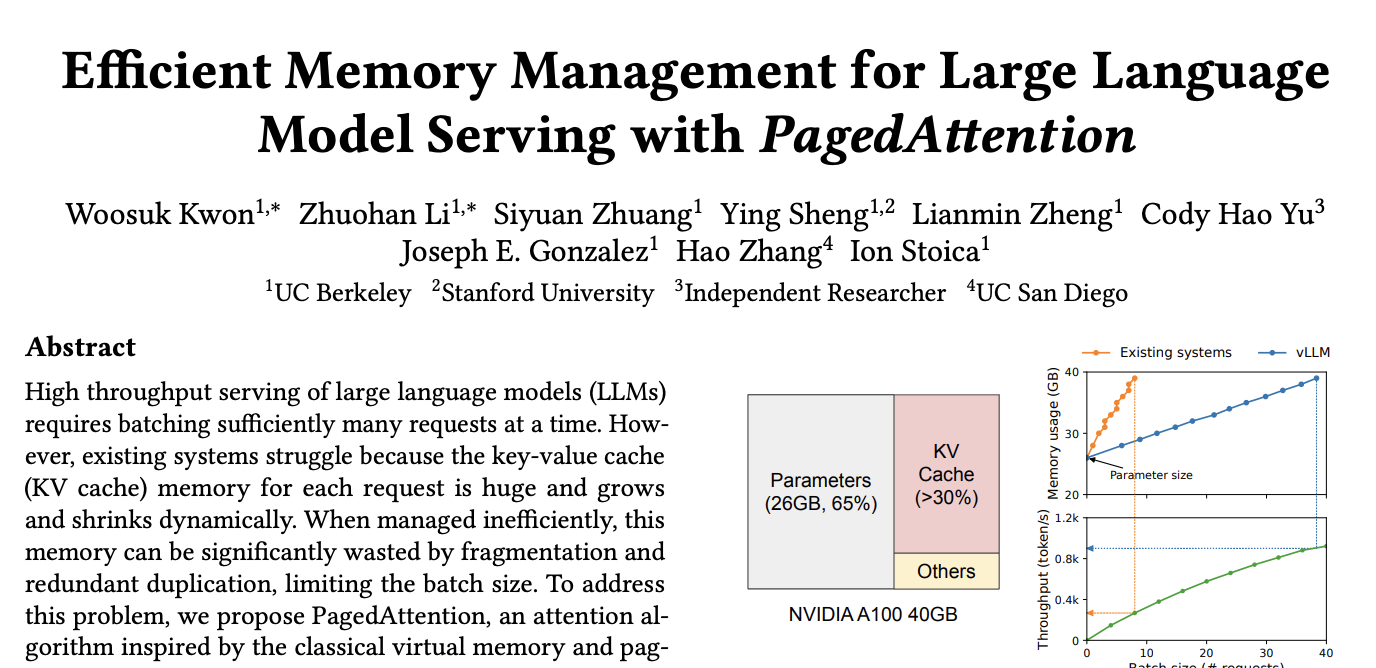

在大模型推理时，按照可生成最长序列长度分配显存。

造成三种类型的浪费：

1. kv cache预分配，但不会用到。
2. kc cache预分配，但尚未用到。
3. 显存之间的间隔碎片，不足以预分配给下一个文本生成。

利用率只有  
20%-40%


![image.png](memory-waste-diagram.svg)

### 6.1.1 page attention

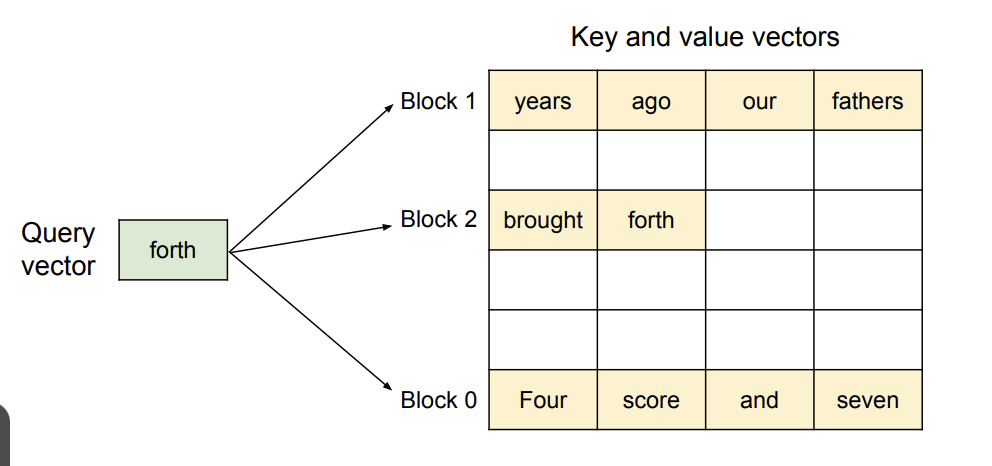

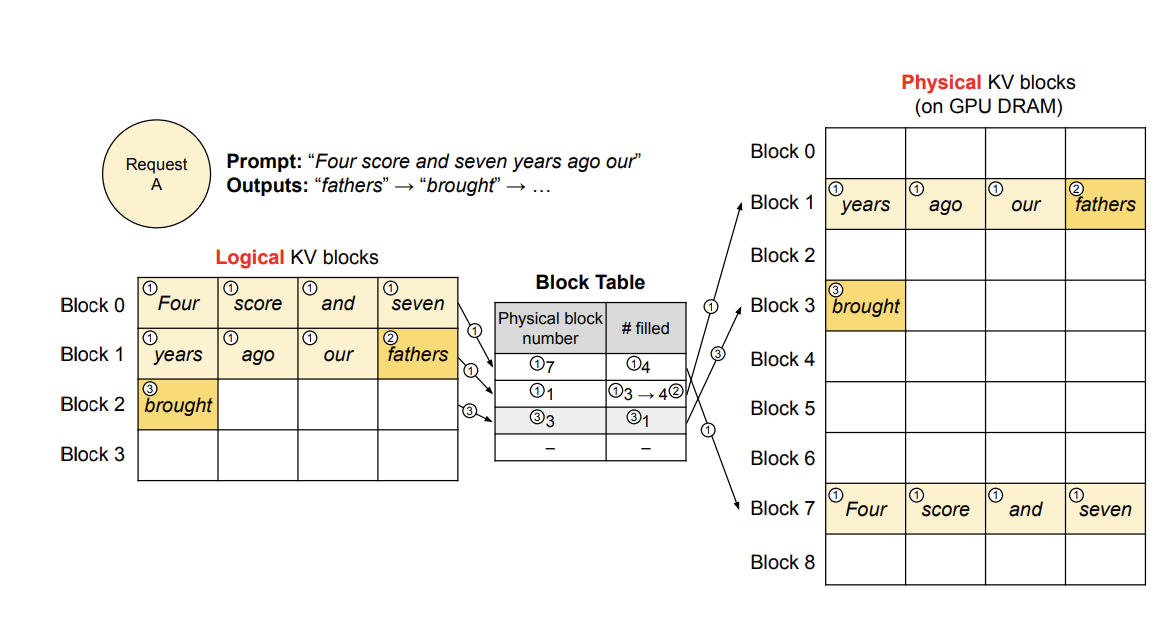

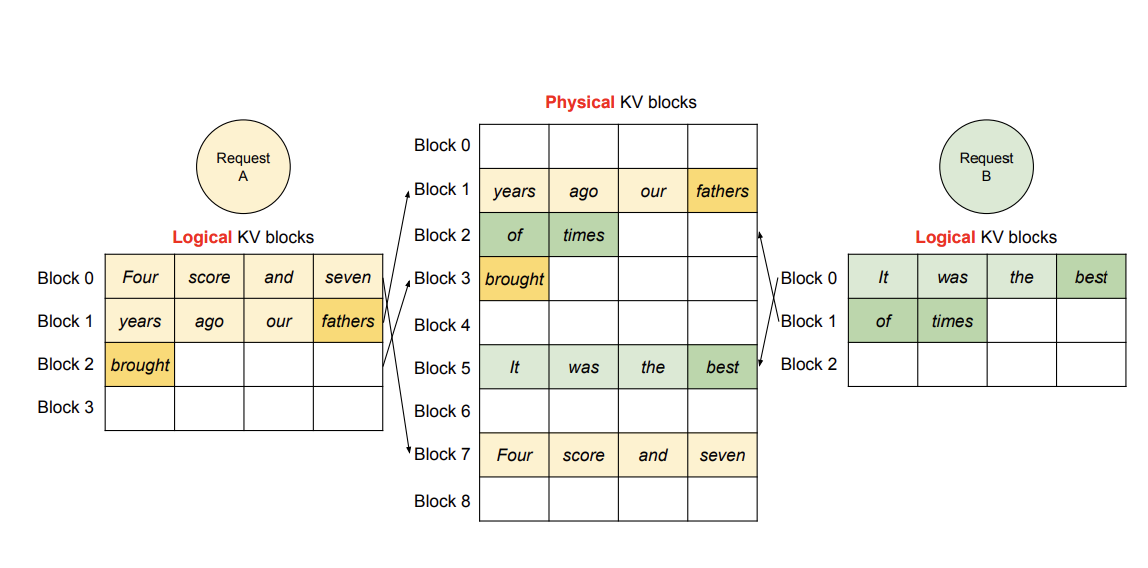

**核心问题：**

*   跑大模型（像 GPT）时，最占显存的是 KVCache。
*   传统的做法（比如 Hugging Face Transformers）是给每个用户请求预先分配一大块连续的显存空间来存 KVCache，不管这个请求最终生成多长的文本。
*   这就像你订酒店，不管住几天，酒店都必须从第一天起就把你可能住满一个月的房间全部锁定给你，别人不能用。结果就是：
    *   **大量浪费**：如果用户只生成很短的文本，大部分预留空间都空着。
    *   **内存碎片**：显存被分割成很多小块，即使总空闲显存很多，也可能因为没有足够大的 *连续* 块而无法服务新请求。

**PagedAttention 的解决方案（像操作系统的内存管理）：**

1.  **不连续存储**：PagedAttention 不再要求 KVCache 必须存在一大块 *连续* 的显存里。
2.  **分成小块（Pages）**：它把 KVCache 切成很多个固定大小的小块（叫做 "Page" 或 "Block"）。这些小块可以存储在显存中任何不连续的位置。
3.  **页表（Page Table）**：为每个请求维护一个“目录”或“页表”。这个表记录了逻辑上的 KVCache 位置（比如第 N 个 Token 的 KV 对）实际存储在哪个物理小块（Page）里。
4.  **按需分配**：只有当需要存储新的 Token 的 KVCache 时，才分配一个新的小块（Page），并更新页表。

**好处：**

*   **几乎没有浪费**：按需分配小块，用到哪里就分配到哪里，大大减少了内部的内存浪费。
*   **灵活管理**：小块更容易在显存中找到位置，减少了内存碎片问题，能同时服务更多请求。
*   **高效共享（关键！）**：对于多个请求有相同前缀（比如同一个 prompt，或者 Beam Search/Parallel Sampling），它们可以共享存储相同前缀 KVCache 的物理小块（Pages）。只有当生成的内容开始不同时，才需要为不同的分支分配新的小块。这极大地节省了显存和计算量。

**简单来说：** PagedAttention 就是把大模型的 KVCache 像管理电脑内存一样，分成小页（Page）来管理，哪里有空就放哪里，并且允许多个请求共享相同内容的页面，从而极大地提高了显存利用率和系统吞吐量。

---

### 6.1.2 共享kv blocks

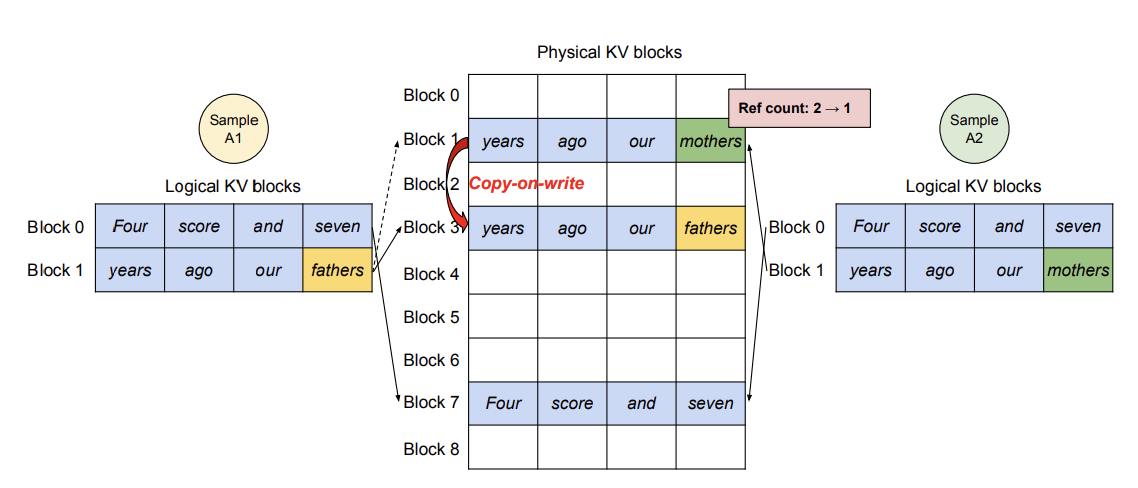

想象一下：

1.  **AI写作文（生成文本）：** AI写长作文（比如GPT模型生成文本）时，需要记住前面写过的内容（这就是所谓的KV Cache），这样才知道接下来写啥。这个“记忆”会占用很多“内存”（显存）。
2.  **传统方法（浪费内存）：** 以前，每个请AI写作文的请求，都得单独给它一大块“内存”来存放这个“记忆”，不管它作文写多长，内存都先按最长的准备好，很浪费。就像给每个小学生发一大叠稿纸，即使他只写几个字。
3.  **vLLM的聪明办法（分页内存 PagedAttention）：** vLLM觉得这样太浪费了。它把大块内存切成很多小块（叫做**Blocks**），像活页纸一样。AI写作文时，写多少就给多少“活页纸”（Blocks）。这样就不浪费了。
4.  **共享KV Blocks：** vLLM发现，如果好几个人让AI写的作文开头部分一模一样（比如都用了同一个很长的指示或者开头），那这部分的“记忆”（KV Cache）其实也是一模一样的。
    *   **vLLM就想：** 干嘛要给每个人都复制一份相同的“开头记忆”呢？多浪费纸（内存块）啊！
    *   **它的做法：** 对于这些完全相同的部分，让这些不同的请求**共用**同一份“记忆”存放在的那些“小内存块”（KV Blocks）里。就像几个学生要抄写同一篇课文的前几段，他们可以一起看**同一本书**（共享的Blocks），而不是每个人都发一本复印件。
    *   当他们的作文后面开始写不一样的内容时，再给他们各自新的、独立的“活页纸”（Blocks）。

**总结一下：**

**vLLM的共享KV Blocks，就是当多个不同的AI写作任务有相同的前缀（开头部分）时，让它们共同使用存储这部分“记忆”的内存小块，而不是各自复制一份。**

**最大好处：** 极大地节省了宝贵的显存，可以让GPU同时处理更多的写作任务，效率大大提高

### 6.1.3 vllm的效果

1.  **吞吐量 (Throughput) 提升:**
    *   **相比 Hugging Face Transformers (TGI - Text Generation Inference) 等基线系统：** vLLM 宣称可以实现 **高达 24 倍** 的吞吐量提升。这个数字通常是在特定的基准测试条件下（例如，特定的模型、硬件、以及请求分布，尤其是当 KV 缓存成为主要瓶颈时）得到的峰值结果。
    *   **在实际应用中：** 更常见的吞吐量提升范围可能在 **2 倍到 10 倍** 之间，具体取决于工作负载。对于需要处理大量并发请求、且请求的提示（prompt）长度和生成长度变化较大的场景，vLLM 的优势尤为明显。
    *   **核心原因：** PagedAttention 极大地减少了 KV 缓存的内存碎片，提高了显存利用率（接近理论上限），使得 GPU 能够容纳更多的并发请求。连续批处理则避免了批次中所有请求必须等待最慢请求完成的问题，提高了 GPU 的利用率。

2.  **加速比 (Speedup) / 延迟 (Latency) 改善:**
    *   vLLM 主要优化的是**吞吐量**。对于单个请求的端到端**延迟**，其改善可能不如吞吐量那么惊人，因为模型本身的计算时间是固定的。
    *   然而，在高负载下，由于 vLLM 能够更快地处理等待队列中的请求（更高的吞吐量），**平均请求延迟**（包括排队时间）会显著降低。
    *   PagedAttention 的 KV 缓存共享机制（例如，在 Beam Search 或多个具有相同前缀的请求中）也可以减少冗余计算和内存拷贝，从而在特定场景下降低单个请求的计算延迟。

3.  **显存效率提升:**
    *   这是 vLLM 最核心的优势之一。传统方法可能导致 KV 缓存的显存利用率很低（20%-40%），因为需要预分配连续的大块内存，容易产生内部和外部碎片。
    *   PagedAttention 将 KV 缓存分成块（Pages/Blocks），按需分配，使得显存利用率可以达到 **96% 左右**，接近物理极限。这意味着在相同的 GPU 上可以运行更大的模型，或者在运行相同模型时处理更多的并发请求。

**总结:**

*   vLLM 在**吞吐量**上可以带来显著提升，官方宣称**最高可达 24 倍**，实际常见范围为 **2-10 倍**，具体取决于多种因素。
*   它主要通过 **PagedAttention** 技术大幅提高**显存利用率**（可达 96%），并结合**连续批处理**等优化实现。
*   在高负载下，可以显著降低**平均请求延迟**。
*   具体的提升效果需要根据你的**具体应用场景**（模型、硬件、请求模式、批处理大小等）进行**实际测试**才能确定。

因此，不能简单地说 vLLM 能固定加速多少倍，但可以说它在 LLM 推理优化方面是一个非常有效的解决方案，尤其是在提高吞吐量和显存效率方面表现突出。